Description...

In [60]:
import sys
sys.path.append('/lhome/ific/c/ccortesp/Analysis/')

from libs import crudo

from   iminuit import Minuit
from   iminuit.cost import LeastSquares
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from   scipy.optimize import curve_fit
from   scipy.signal import find_peaks
import yaml

# Styling Plot
# crudo.pt.papers_plot_style()
crudo.pt.ccortesp_plot_style()
# PRELIM_LOGO = np.asarray(Image.open('/lhome/ific/c/ccortesp/Analysis/images/next_logo_preliminary.png'))

%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Configurations

In [61]:
# Conditions
iso = 'Xe'
cath_hv = 32e3

# Paths
RUNS_INFO_FILENAME = "/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/utilities/runs_information.csv"
BASE_PATH = '/lhome/ific/c/ccortesp/Data/Cmmssnng/h5/'
SOPH_PATH = '/lhome/ific/c/ccortesp/Data/Alphas/'

# Important dates
HOT_GETTER_DAY = 1792148400

In [62]:
RUNS_INFO_DF = pd.read_csv(RUNS_INFO_FILENAME, index_col="run_number").reset_index()

mask = (RUNS_INFO_DF["cath_voltage"] >= cath_hv) & (RUNS_INFO_DF["isotope"] == iso)

In [63]:
for idx, row in RUNS_INFO_DF.iterrows():
  run_id = int(row["run_number"])

  filename = f"run_{run_id}_ldc1_sophronia.h5"
  filepath = os.path.join(SOPH_PATH, filename)

  # Check if the Sophronia file actually exists before reading
  if not os.path.exists(filepath):
    print(f"  [!] Warning: Sophronia file for run {run_id} not found. Setting NaN.")
    RUNS_INFO_DF.loc[RUNS_INFO_DF["run_number"] == run_id, "date_cv"]  = np.nan
    RUNS_INFO_DF.loc[RUNS_INFO_DF["run_number"] == run_id, "date_err"] = np.nan
    continue

  try:
    temp_df = pd.read_hdf(filepath, key="/DST/Events")
    n_evts = temp_df["event"].nunique()

    time_cv  = temp_df["time"].mean()
    time_err = temp_df["time"].std() / np.sqrt(n_evts) if n_evts > 1 else 0.0

    RUNS_INFO_DF.loc[RUNS_INFO_DF["run_number"] == run_id, "date_cv"]  = time_cv
    RUNS_INFO_DF.loc[RUNS_INFO_DF["run_number"] == run_id, "date_err"] = time_err

    print(f"  [✓] Processed Run {run_id} (Events: {n_evts})")

  except Exception as e:
    print(f"  [!] Error processing run {run_id} from file {filename}: {e}"
           " Setting NaN.")
    RUNS_INFO_DF.loc[RUNS_INFO_DF["run_number"] == run_id, "date_cv"]  = np.nan
    RUNS_INFO_DF.loc[RUNS_INFO_DF["run_number"] == run_id, "date_err"] = np.nan

print("\nDone!")

  [✓] Processed Run 16047 (Events: 2046)
  [✓] Processed Run 16057 (Events: 2034)
  [✓] Processed Run 14739 (Events: 48827)
  [✓] Processed Run 14840 (Events: 4467)
  [✓] Processed Run 16081 (Events: 12777)
  [✓] Processed Run 16082 (Events: 12945)
  [✓] Processed Run 16083 (Events: 13240)
  [✓] Processed Run 16089 (Events: 10122)
  [✓] Processed Run 16090 (Events: 8066)
  [✓] Processed Run 16103 (Events: 39013)
  [✓] Processed Run 16104 (Events: 39031)
  [✓] Processed Run 16105 (Events: 38853)
  [✓] Processed Run 16106 (Events: 39131)
  [✓] Processed Run 16114 (Events: 41520)
  [✓] Processed Run 16116 (Events: 31471)
  [✓] Processed Run 16117 (Events: 32668)
  [✓] Processed Run 16118 (Events: 32419)
  [✓] Processed Run 16120 (Events: 32429)
  [✓] Processed Run 16121 (Events: 32559)
  [✓] Processed Run 16122 (Events: 33217)
  [✓] Processed Run 16123 (Events: 29241)
  [✓] Processed Run 16153 (Events: 25560)
  [✓] Processed Run 16158 (Events: 22547)
  [✓] Processed Run 16166 (Events: 210

In [64]:
RUNS_INFO_DF = RUNS_INFO_DF[mask].copy().dropna()
RUNS_INFO_DF

,run_number,pressure,cath_voltage,gate_voltage,duration,OK,LOST,isotope,date_cv,date_err
8,16090,9.007,32996.2,9701.9,8375.0,300098.0,941138.0,Xe,1.790086e+09,6.675528
9,16103,8.971,32995.9,10002.1,55374.0,2037460.0,6810658.0,Xe,1.790907e+09,81.930107
10,16104,8.970,32995.9,10002.0,90569.0,3344091.0,11226288.0,Xe,1.790993e+09,129.724758
11,16105,8.968,32996.3,10002.0,83300.0,3091226.0,10505095.0,Xe,1.791079e+09,120.505288
13,16114,8.921,32996.8,10501.9,89109.0,3373930.0,12665908.0,Xe,1.791334e+09,127.468177
15,16117,8.898,32996.8,11501.5,80335.0,3016429.0,11591422.0,Xe,1.791452e+09,19.451878
16,16118,8.889,32997.1,11501.4,94198.0,3573825.0,13769435.0,Xe,1.791573e+09,149.305838
17,16120,8.882,32997.0,11501.4,86371.0,3285747.0,12738160.0,Xe,1.791738e+09,135.824766
18,16121,8.879,32997.1,11501.4,104930.0,3994921.0,15535779.0,Xe,1.791831e+09,164.592279
19,16122,8.869,32997.0,12001.5,69722.0,2672089.0,10742152.0,Xe,1.791934e+09,109.362187


# Trigger

In [65]:
# ----- Radon Decay Data ----- #
Date_cv  = []
Date_err = []
Rate_cv  = []
Rate_err = []
Run_numbers = []

for i, entry in RUNS_INFO_DF.iterrows():

    # Run info
    run_id = entry["run_number"]
    run_date_cv  = entry["date_cv"]
    run_date_err = entry["date_err"]
    run_long = entry["duration"]
    run_OK   = entry["OK"]
    run_LOST = entry["LOST"]

    if run_id in [14716, 14835, 14814]:  
        print(f"Skipping run {run_id}... plotting purposes")  
        continue

    Run_numbers.append(run_id)
    
    # Mean date + error for each run
    Date_cv.append(run_date_cv)
    Date_err.append(run_date_err)
    
    # Real rate + error for each run
    run_trigg = run_OK + run_LOST
    rate_CV   = run_trigg / run_long
    rate_stat = np.sqrt(run_trigg) / run_long
    Rate_cv.append(rate_CV)
    Rate_err.append(np.sqrt(rate_stat**2))

    print(f"Run {run_id}: Rate = {rate_CV:.4f} ± {np.sqrt(rate_stat**2):.4f} Hz")

Run 16090: Rate = 148.2073 ± 0.1330 Hz
Run 16103: Rate = 159.7883 ± 0.0537 Hz
Run 16104: Rate = 160.8760 ± 0.0421 Hz
Run 16105: Rate = 163.2211 ± 0.0443 Hz
Run 16114: Rate = 180.0024 ± 0.0449 Hz
Run 16117: Rate = 181.8367 ± 0.0476 Hz
Run 16118: Rate = 184.1149 ± 0.0442 Hz
Run 16120: Rate = 185.5242 ± 0.0463 Hz
Run 16121: Rate = 186.1308 ± 0.0421 Hz
Run 16122: Rate = 192.3961 ± 0.0525 Hz
Run 16123: Rate = 143.5751 ± 0.0424 Hz
Run 16153: Rate = 150.2807 ± 0.0500 Hz
Run 16158: Rate = 87.6461 ± 0.0319 Hz
Run 16166: Rate = 74.6976 ± 0.0294 Hz
Run 16172: Rate = 58.0948 ± 0.0328 Hz
Run 16185: Rate = 50.3163 ± 0.0241 Hz
Run 16186: Rate = 46.0314 ± 0.0226 Hz


In [68]:
# ----- Exponential + Constant Fit ----- #
# Preliminary
Date_cv  = np.array(Date_cv)
Date_err = np.array(Date_err)
Rate_cv  = np.array(Rate_cv)
Rate_err = np.array(Rate_err)

# Masking: select specific data
HG_time = (Date_cv >= HOT_GETTER_DAY)

x_data = Date_cv[HG_time]
y_data = Rate_cv[HG_time]
y_err  = Rate_err[HG_time]

# Shifted time
x_shift = (x_data - x_data[0]) / 3600  # In [hr] for numeric stability

# Define the cost function + initial guess
least_squares = LeastSquares(x_shift, y_data, y_err, crudo.ff.exponential_decay)
init_guess    = [y_data.max(), (x_shift.max() - x_shift.min()) / 2, y_data.min()]
print(f'Initial guess: N0 = {init_guess[0]:.4f} Hz, τ = {init_guess[1]:.4f} hr, b = {init_guess[2]:.4f} Hz')

# Define the Minuit object
m = Minuit(least_squares, *init_guess)

# Minimization process of the cost function and error estimation
m.migrad()
m.hesse()

# Results
popt = m.values;  perr = m.errors
print(f"\nFit results:")
print(f"  N0 = ({popt['N0']:.4f} ± {perr['N0']:.4f}) Hz")
print(f"  τ  = ({popt['tau']:.4f} ± {perr['tau']:.4f}) hr")
print(f"  b  = ({popt['b']:.4f} ± {perr['b']:.4f}) Hz")

# Reduced chi-square
chi2 = m.fval
ndof = len(x_shift) - m.nfit
print(f"\nχ² / ndof = {chi2 / ndof:.4f}")
# print(f"\nχ² = {chi2:.4f}")

# Half-life
CV_lambda    = (popt['tau'] * np.log(2)) / 24  # In [d] to compare
Error_lambda = (perr['tau'] * np.log(2)) / 24
print(f"\nHalf-life = ({CV_lambda:.4f} ± {Error_lambda:.4f}) d")

# Fit
x_fit = np.linspace(x_shift.min(), x_shift.max(), 1000) * 3600 + x_data[0]  # In [s]
y_fit = crudo.ff.exponential_decay(np.linspace(x_shift.min(), x_shift.max(), 1000), *popt)

Initial guess: N0 = 87.6461 Hz, τ = 69.3523 hr, b = 46.0314 Hz

Fit results:
  N0 = (82.3844 ± 0.4507) Hz
  τ  = (189.3035 ± 1.5397) hr
  b  = (5.8079 ± 0.4635) Hz

χ² / ndof = 2192.0025

Half-life = (5.4673 ± 0.0445) d


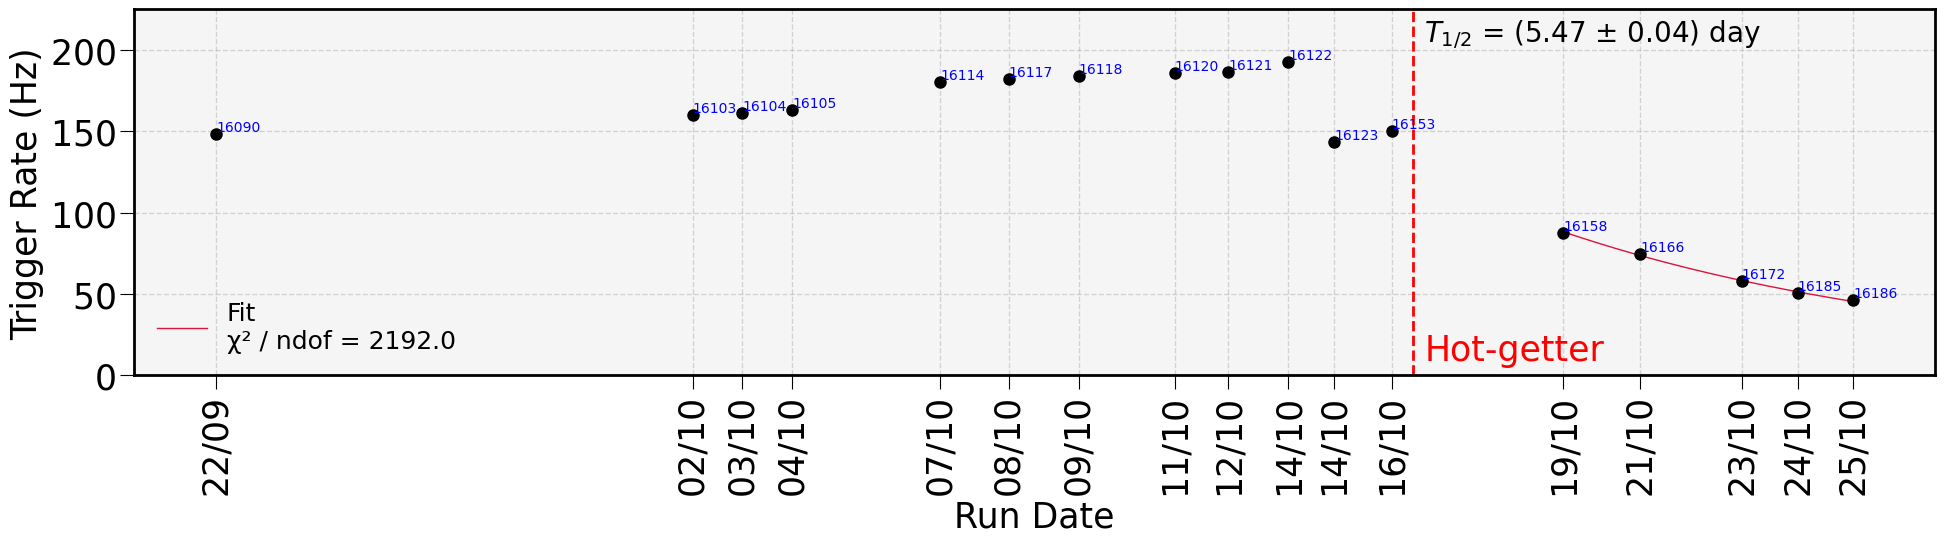

In [74]:
# ----- Plotting ---- #
fig, ax = plt.subplots(figsize=(20, 6))

# Data
plt.errorbar(Date_cv, Rate_cv, xerr=Date_err, yerr=Rate_err, fmt='o', c='black', ecolor='black')
for x, y, run_id in zip(Date_cv, Rate_cv, Run_numbers):
    plt.text(x, y, str(run_id), fontsize=10, ha='left', va='bottom', color='blue')  # Run number near the point

# Fit
plt.plot(x_fit, y_fit, color=crudo.pt.hist_colors[(1) % len(crudo.pt.hist_colors)], label=f'Fit\nχ² / ndof = {chi2 / ndof:.1f}')

# ----- Styling ----- #
# Important text
plt.axvline(x=HOT_GETTER_DAY, c='red', ls='--', lw=2.0)
plt.text(HOT_GETTER_DAY+2e4, 5, 'Hot-getter', c='red', va='bottom', ha='left')
plt.text(HOT_GETTER_DAY+2e4, 200, r'$T_{1/2}$'f' = ({CV_lambda:.2f} ± {Error_lambda:.2f}) day', va='bottom', ha='left', fontsize=20)

# Axes
plt.xlabel('Run Date')
x_labels = [crudo.ut.epoch_converter(t, h=False) for t in Date_cv]  # Convert x-axis bin edges to readable time format
plt.xticks(Date_cv, x_labels, rotation=90, ha='center')
plt.ylabel('Trigger Rate (Hz)')
plt.ylim(0, 225)
# plt.title('Trigger Real Rate')
plt.legend(loc='lower left', fontsize=18)

plt.grid(True)
plt.gca().set_facecolor("whitesmoke")
plt.tight_layout()
plt.show()